# v4 Hydrostatics — NavalToolbox



In [1]:
MASS_KG = 77  # EDIT THIS: whole boat mass (kg).
MASS_OFFSETS_KG = [-10, -5, 0, 5, 10, 20]


In [2]:
from pathlib import Path
import sys
import site
import importlib
from importlib.metadata import version

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'prop_motor_battery').is_dir())
HERE = ROOT / 'hull/hydrostatics/v4-2026-10-30'
if sys.version_info[:2] != (3, 13):
    raise RuntimeError('Select a Python 3.13 kernel for this notebook.')
# Make the project-local installation available in the existing Python 3.13 kernel.
site.addsitedir(str(ROOT / 'hull/hydrostatics/.venv/lib/python3.13/site-packages'))
import navaltoolbox
import matplotlib.pyplot as plt
from IPython.display import display
if str(HERE) not in sys.path:
    sys.path.insert(0, str(HERE))
import run_navaltoolbox as hydro
hydro = importlib.reload(hydro)
print(f"Python {sys.version.split()[0]} | NavalToolbox {version('navaltoolbox')}")


Python 3.13.16 | NavalToolbox 0.9.3


In [3]:
results, metadata = hydro.calculate(MASS_OFFSETS_KG, mass_kg=MASS_KG)
display(results.round(3))


,added_mass_kg,mass_kg,mass_lb,volume_l,extra_volume_in3,draft_midship_in,draft_aft_in,draft_forward_in,trim_bow_down_deg,heel_deg,freeboard_min_in,waterline_length_in,submerged_length_in,wetted_area_in2,waterplane_area_in2,gm_transverse_in,mass_balance_relative_error,dry_hull_assumption_ok
0,-10.0,67.0,147.710,67.126,-611.338,6.412,7.441,5.382,-1.638,0.000,4.557,62.694,62.694,1431.876,982.136,3.841,0.0,True
1,-5.0,72.0,158.733,72.133,-305.669,6.683,7.864,5.502,-1.879,0.000,4.134,62.997,62.997,1483.515,1005.659,3.939,0.0,True
2,0.0,77.0,169.756,77.135,0.000,6.947,8.277,5.617,-2.115,0.000,3.721,63.287,63.287,1534.363,1028.987,4.053,0.0,True
3,5.0,82.0,180.779,82.149,305.669,7.206,8.682,5.731,-2.347,0.001,3.315,63.567,63.567,1584.629,1052.174,4.180,0.0,True
4,10.0,87.0,191.802,87.160,611.338,7.460,9.079,5.840,-2.576,0.000,2.918,63.818,63.818,1634.187,1075.159,4.317,0.0,True
5,20.0,97.0,213.848,97.179,1222.676,7.951,9.849,6.054,-3.017,0.000,2.148,64.299,64.299,1731.338,1120.436,4.612,0.0,True


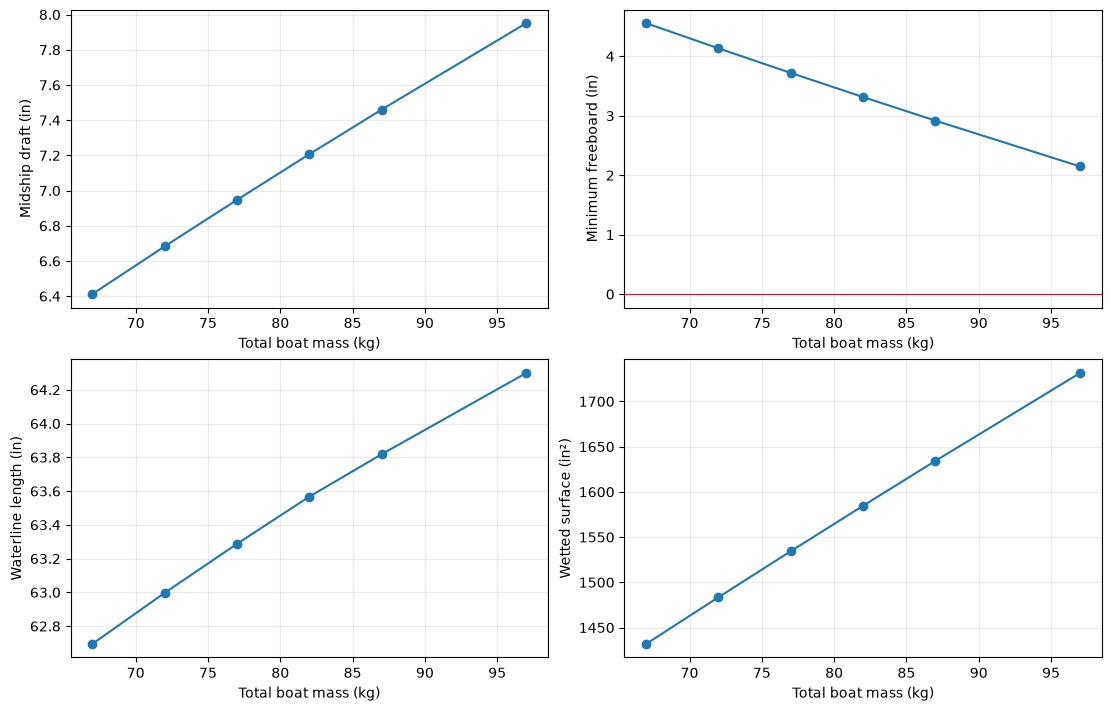

In [4]:
fig = hydro.make_plots(results)
plt.show()
